# Training MedMNIST Net Model
Training script for MedMNIST Net model on PathMNIST and Breast Cancer datasets

Uses the exact same configuration and preprocessing as the ResNet18 models

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset, ConcatDataset
from torchvision import transforms, models
from torchvision.datasets import ImageFolder
from medmnist import PathMNIST
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import matplotlib.pyplot as plt
import numpy as np

In [4]:
# Configuration (same as train.ipynb)
BATCH_SIZE = 128
NUM_EPOCHS = 20
LEARNING_RATE = 0.001

# Device selection (same as train.ipynb)
if torch.backends.mps.is_available():
    device = torch.device('mps')
elif torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

print(f'Using device: {device}')

Using device: mps


# Part 1: PathMNIST Training

In [5]:
# Transform (exact same as train.ipynb)
transform = transforms.Compose([
    transforms.Resize((100, 100)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load PathMNIST dataset
train = PathMNIST(split="train", transform=transform, download=False)
val = PathMNIST(split="val", transform=transform, download=False)
test = PathMNIST(split="test", transform=transform, download=False)

In [6]:
# Dataset info
print(f"Training samples: {len(train)}")
print(f"Validation samples: {len(val)}")
print(f"Test samples: {len(test)}")
print(f"Image shape: {train[0][0].shape}")
print(f"Number of classes: {len(train.info['label'])}")
print(f"Class labels: {train.info['label']}")

Training samples: 89996
Validation samples: 10004
Test samples: 7180
Image shape: torch.Size([3, 100, 100])
Number of classes: 9
Class labels: {'0': 'adipose', '1': 'background', '2': 'debris', '3': 'lymphocytes', '4': 'mucus', '5': 'smooth muscle', '6': 'normal colon mucosa', '7': 'cancer-associated stroma', '8': 'colorectal adenocarcinoma epithelium'}


In [7]:
# Create combined training dataset (same as train.ipynb)
full_train = ConcatDataset([train, val])

# Create data loaders
train_loader = DataLoader(full_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
test_loader = DataLoader(test, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f'Training batches: {len(train_loader)}')

Training batches: 782


In [8]:
# Define MedMNIST baseline Net model
class Net(nn.Module):
    def __init__(self, in_channels, num_classes):
        super(Net, self).__init__()
        
        self.layer1 = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=3),
            nn.BatchNorm2d(16),
            nn.ReLU())
        
        self.layer2 = nn.Sequential(
            nn.Conv2d(16, 16, kernel_size=3),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2))
        
        self.layer3 = nn.Sequential(
            nn.Conv2d(16, 64, kernel_size=3),
            nn.BatchNorm2d(64),
            nn.ReLU())
        
        self.layer4 = nn.Sequential(
            nn.Conv2d(64, 64, kernel_size=3),
            nn.BatchNorm2d(64),
            nn.ReLU())
        
        self.layer5 = nn.Sequential(
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2))
        
        self.fc = nn.Sequential(
            nn.Linear(64 * 22 * 22, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes))
    
    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.layer5(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

# Initialize MedMNIST Net model
num_classes_pathmnist = len(train.info['label'])
pathmnist_model = Net(in_channels=3, num_classes=num_classes_pathmnist)
pathmnist_model = pathmnist_model.to(device)
print(f'MedMNIST Net loaded with {num_classes_pathmnist} output classes')

MedMNIST Net loaded with 9 output classes


In [9]:
# Loss function and optimizer (same as train.ipynb)
pathmnist_criterion = nn.CrossEntropyLoss()
pathmnist_optimizer = optim.SGD(
    pathmnist_model.parameters(),
    lr=LEARNING_RATE,
    momentum=0.9,
    weight_decay=1e-4
)

In [10]:
# Training loop for PathMNIST
pathmnist_history = {'train_loss': [], 'train_acc': []}

for epoch in range(NUM_EPOCHS):
    print(f'\nEpoch {epoch+1}/{NUM_EPOCHS}')
    print('-' * 50)
    
    # Training phase
    pathmnist_model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0
    
    for images, labels in tqdm(train_loader, desc='Training PathMNIST'):
        images = images.to(device)
        labels = labels.squeeze().long().to(device)
        
        pathmnist_optimizer.zero_grad()
        outputs = pathmnist_model(images)
        loss = pathmnist_criterion(outputs, labels)
        loss.backward()
        pathmnist_optimizer.step()
        
        train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()
    
    epoch_train_loss = train_loss / train_total
    epoch_train_acc = 100 * train_correct / train_total
    
    # Save history
    pathmnist_history['train_loss'].append(epoch_train_loss)
    pathmnist_history['train_acc'].append(epoch_train_acc)
    
    print(f'Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}%')

print(f'\nPathMNIST Training complete!')


Epoch 1/20
--------------------------------------------------


Training PathMNIST: 100%|██████████| 782/782 [02:02<00:00,  6.36it/s]


Train Loss: 0.7070 | Train Acc: 74.78%

Epoch 2/20
--------------------------------------------------


Training PathMNIST: 100%|██████████| 782/782 [02:22<00:00,  5.48it/s]


Train Loss: 0.3993 | Train Acc: 85.69%

Epoch 3/20
--------------------------------------------------


...

Train Loss: 0.0284 | Train Acc: 99.05%

Epoch 19/20
--------------------------------------------------


Training PathMNIST: 100%|██████████| 782/782 [03:11<00:00,  4.08it/s]


Train Loss: 0.0246 | Train Acc: 99.21%

Epoch 20/20
--------------------------------------------------


Training PathMNIST: 100%|██████████| 782/782 [03:15<00:00,  3.99it/s]

Train Loss: 0.0273 | Train Acc: 99.08%

PathMNIST Training complete!


In [11]:
# Evaluate on test set
pathmnist_model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc='Testing PathMNIST'):
        images = images.to(device)
        labels = labels.squeeze().long().to(device)
        
        outputs = pathmnist_model(images)
        _, predicted = torch.max(outputs, 1)
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

pathmnist_test_acc = 100 * test_correct / test_total
print(f'PathMNIST Test Accuracy: {pathmnist_test_acc:.2f}%')

Testing PathMNIST: 100%|██████████| 57/57 [00:15<00:00,  3.66it/s]

PathMNIST Test Accuracy: 83.51%


In [ ]:
# Save model with test accuracy in filename
model_filename = f"other/models/medmnist_net_full_{pathmnist_test_acc:.2f}_pathmnist.pth"
torch.save(pathmnist_model.state_dict(), model_filename)
print(f"PathMNIST model saved as {model_filename}")

PathMNIST model saved as ../models/medmnist_net_full_83.51_pathmnist.pth


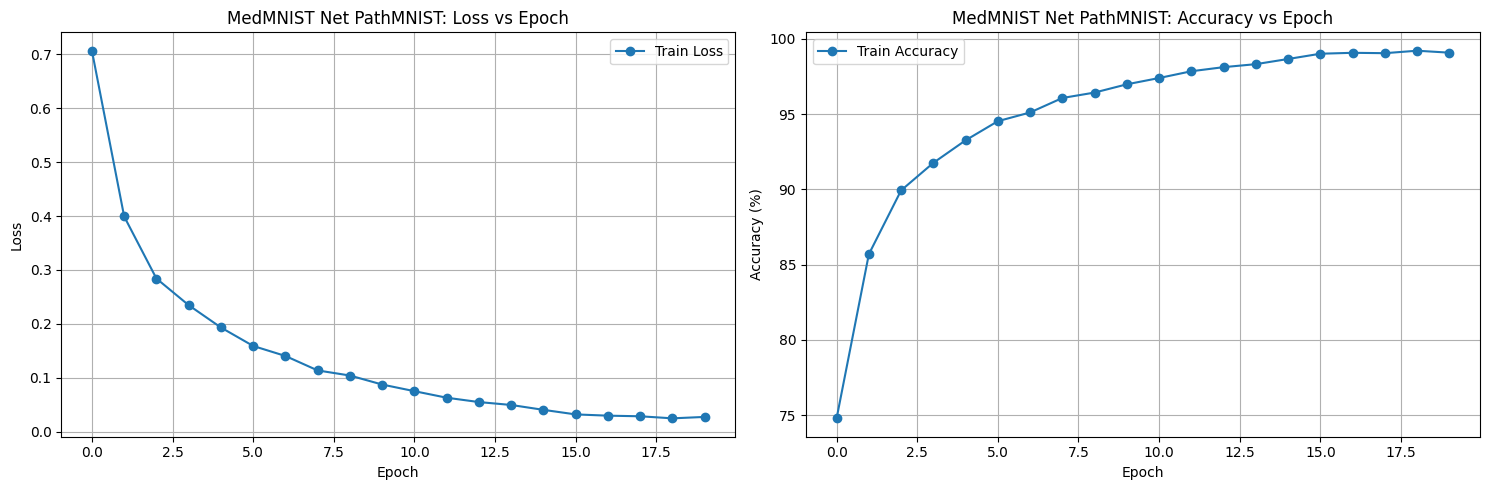

In [13]:
# Plot training history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

ax1.plot(pathmnist_history['train_loss'], label='Train Loss', marker='o')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('MedMNIST Net PathMNIST: Loss vs Epoch')
ax1.legend()
ax1.grid(True)

ax2.plot(pathmnist_history['train_acc'], label='Train Accuracy', marker='o')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_title('MedMNIST Net PathMNIST: Accuracy vs Epoch')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

# Part 2: Breast Cancer Training

In [14]:
# Define transforms for breast cancer dataset (same as train.ipynb)
bc_transform = transforms.Compose([
    transforms.Resize((100, 100)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load full dataset
data_dir = '../data'
full_dataset = ImageFolder(root=data_dir, transform=bc_transform)

print(f"Total breast cancer images: {len(full_dataset)}")
print(f"Classes: {full_dataset.classes}")
print(f"Class to index mapping: {full_dataset.class_to_idx}")

Total breast cancer images: 7909
Classes: ['benign', 'malignant']
Class to index mapping: {'benign': 0, 'malignant': 1}


In [15]:
# Split dataset into train, validation, and test sets (same logic as train.ipynb)
indices = list(range(len(full_dataset)))
targets = [full_dataset.targets[i] for i in indices]

print(f"Total available images: {len(full_dataset)}")

# Calculate split sizes based on available data
total_samples = len(full_dataset)
if total_samples >= 9109:
    train_size = 7000
    val_size = 1109
    test_size = 1000
else:
    # Proportional split maintaining the ratios
    train_size = int(total_samples * 0.7684)  # 7000/9109
    val_size = int(total_samples * 0.1218)    # 1109/9109
    test_size = total_samples - train_size - val_size

print(f"Using split - Train: {train_size}, Val: {val_size}, Test: {test_size}")

# Split: First get training set
train_indices, temp_indices = train_test_split(
    indices, train_size=train_size, stratify=targets, random_state=42
)

# Then split remaining into val and test
temp_targets = [targets[i] for i in temp_indices]
remaining = len(temp_indices)
val_ratio = val_size / (val_size + test_size)
val_actual = int(remaining * val_ratio)

val_indices, test_indices = train_test_split(
    temp_indices, train_size=val_actual, stratify=temp_targets, random_state=42
)

Total available images: 7909
Using split - Train: 6077, Val: 963, Test: 869


In [16]:
# Create datasets
bc_train_dataset = Subset(full_dataset, train_indices)
bc_val_dataset = Subset(full_dataset, val_indices)
bc_test_dataset = Subset(full_dataset, test_indices)

# Don't use validation during training - only train and test
bc_full_train = bc_train_dataset

# Create data loaders
bc_train_loader = DataLoader(bc_full_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
bc_test_loader = DataLoader(bc_test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Training batches: {len(bc_train_loader)}")
print(f"Breast Cancer - Train: {len(bc_train_dataset)}, Val: {len(bc_val_dataset)}, Test: {len(bc_test_dataset)}")

Training batches: 48
Breast Cancer - Train: 6077, Val: 962, Test: 870


In [17]:
# Initialize MedMNIST Net model for Breast Cancer (Binary Classification)
bc_model = Net(in_channels=3, num_classes=2)
bc_model = bc_model.to(device)
print(f'MedMNIST Net for Breast Cancer loaded with 2 output classes (Benign/Malignant)')

MedMNIST Net for Breast Cancer loaded with 2 output classes (Benign/Malignant)


In [18]:
# Loss function and optimizer (same as train.ipynb)
bc_criterion = nn.CrossEntropyLoss()
bc_optimizer = optim.SGD(
    bc_model.parameters(),
    lr=LEARNING_RATE,
    momentum=0.9,
    weight_decay=1e-4
)

In [19]:
# Training loop for Breast Cancer
bc_history = {'train_loss': [], 'train_acc': []}

for epoch in range(NUM_EPOCHS):
    print(f'\nEpoch {epoch+1}/{NUM_EPOCHS}')
    print('-' * 50)
    
    # Training phase
    bc_model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0
    
    for images, labels in tqdm(bc_train_loader, desc='Training BC'):
        images = images.to(device)
        labels = labels.to(device)
        
        bc_optimizer.zero_grad()
        outputs = bc_model(images)
        loss = bc_criterion(outputs, labels)
        loss.backward()
        bc_optimizer.step()
        
        train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()
    
    epoch_train_loss = train_loss / train_total
    epoch_train_acc = 100 * train_correct / train_total
    
    # Save history
    bc_history['train_loss'].append(epoch_train_loss)
    bc_history['train_acc'].append(epoch_train_acc)
    
    print(f'Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}%')

print(f'\nBreast Cancer Training complete!')


Epoch 1/20
--------------------------------------------------


Training BC: 100%|██████████| 48/48 [00:38<00:00,  1.24it/s]


Train Loss: 0.4750 | Train Acc: 77.60%

Epoch 2/20
--------------------------------------------------


Training BC: 100%|██████████| 48/48 [00:36<00:00,  1.31it/s]


Train Loss: 0.3526 | Train Acc: 84.76%

Epoch 3/20
--------------------------------------------------


...

Train Loss: 0.0778 | Train Acc: 96.97%

Epoch 19/20
--------------------------------------------------


Training BC: 100%|██████████| 48/48 [00:42<00:00,  1.13it/s]


Train Loss: 0.0507 | Train Acc: 98.67%

Epoch 20/20
--------------------------------------------------


Training BC: 100%|██████████| 48/48 [00:42<00:00,  1.13it/s]

Train Loss: 0.0371 | Train Acc: 99.29%

Breast Cancer Training complete!


In [20]:
# Evaluate on test set
bc_model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in tqdm(bc_test_loader, desc='Testing BC'):
        images = images.to(device)
        labels = labels.to(device)
        
        outputs = bc_model(images)
        _, predicted = torch.max(outputs, 1)
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

bc_test_acc = 100 * test_correct / test_total
print(f'Breast Cancer Test Accuracy: {bc_test_acc:.2f}%')

Testing BC: 100%|██████████| 7/7 [00:14<00:00,  2.11s/it]

Breast Cancer Test Accuracy: 89.20%


In [ ]:
# Save model with test accuracy in filename
model_filename = f"other/models/medmnist_net_full_{bc_test_acc:.2f}_bc.pth"
torch.save(bc_model.state_dict(), model_filename)
print(f"Breast Cancer model saved as {model_filename}")

Breast Cancer model saved as ../models/medmnist_net_full_89.20_bc.pth


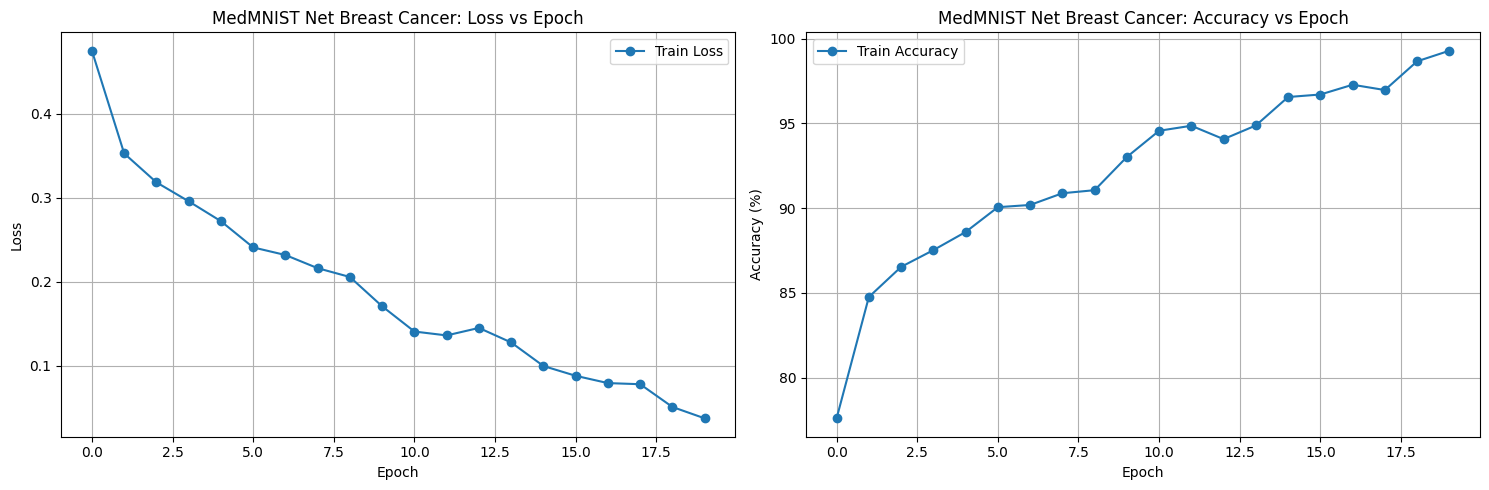

In [22]:
# Plot training history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

ax1.plot(bc_history['train_loss'], label='Train Loss', marker='o')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('MedMNIST Net Breast Cancer: Loss vs Epoch')
ax1.legend()
ax1.grid(True)

ax2.plot(bc_history['train_acc'], label='Train Accuracy', marker='o')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_title('MedMNIST Net Breast Cancer: Accuracy vs Epoch')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# Final Summary
print("\n" + "="*60)
print("TRAINING COMPLETE!")
print("="*60)
print(f"\nPathMNIST Test Accuracy: {pathmnist_test_acc:.2f}%")
print(f"Breast Cancer Test Accuracy: {bc_test_acc:.2f}%")
print(f"\nModels saved in other/models/")


TRAINING COMPLETE!

PathMNIST Test Accuracy: 83.51%
Breast Cancer Test Accuracy: 89.20%

Models saved in ../models/
